# 05. Modelos con estructura

Teórica de series temporales, Analítica de Datos (UdeSA). Este cuaderno acompaña el bloque 5 de la clase.

El mismo ejercicio que en el cuaderno 04: entrenar con los datos del 1/1/2023 al 31/5/2025 y pronosticar del 1 al 28 de junio de 2025. Ahora con modelos que tienen estructura explícita (ARIMA y SARIMA), que usan variables externas (feriados, puentes, lluvia) o que tratan la serie como una tabla (gradient boosting).

Contenido:

1. ARIMA y SARIMA.
2. Elegir el orden: ACF, PACF y AIC.
3. SARIMAX: feriados, puentes y lluvia.
4. Intervalos de predicción con y sin variables externas.
5. Gradient boosting con rezagos.
6. Comparación de todos los modelos.
7. Otras alternativas: Prophet.

In [1]:
import sys

# Dirección de los datos cuando el notebook corre en Colab.
# Si los datos se suben a otro lado, hay que cambiar esta constante.
URL_DATOS_COLAB = "https://raw.githubusercontent.com/ferkrodriguez98/teorica-series-temporales/main/datos_clase/"

EN_COLAB = "google.colab" in sys.modules
BASE = URL_DATOS_COLAB if EN_COLAB else "../datos_clase/"
print("Datos:", BASE)

Datos: ../datos_clase/


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# Colores: tinta para lo observado, rojo para pronósticos y resaltados
TINTA, GRIS, ROJO = "#1f2430", "#9aa0a6", "#c62828"
LINEAS = {"A": "#1a9fd0", "B": "#d7182a", "C": "#1d4f9c", "D": "#008a57", "E": "#6c2c87", "H": "#e0a800"}
ECOBICI = "#d4a017"

warnings.simplefilter("ignore", FutureWarning)   # avisos de cambios en versiones futuras de las librerías

plt.rcParams.update({
    "figure.figsize": (10, 3.6), "figure.dpi": 100, "savefig.bbox": "tight",
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b0b0b0",
    "axes.titlesize": 11.5, "axes.titlelocation": "left", "axes.labelsize": 10,
    "axes.labelcolor": "#444444", "xtick.color": "#555555", "ytick.color": "#555555",
    "legend.frameon": False, "legend.fontsize": 9.5, "lines.linewidth": 1.1,
})

def num(x, dec=0):
    # Número con punto de miles y coma decimal
    return f"{x:,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def pct(x, dec=0):
    return num(100 * x, dec) + " %"

en_millones = FuncFormatter(lambda v, _: num(v / 1e6, 1))
en_miles = FuncFormatter(lambda v, _: num(v / 1e3))

import itertools
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

DIAS3 = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]

## Datos

Una tabla diaria con los pasajeros, el calendario y el clima:

- `feriado`: feriado con descanso obligatorio (sin contar los puentes) que cae de lunes a viernes.
- `puente`: día no laborable con fines turísticos. Según el año, la norma lo define como feriado o como día no laborable (ver el cuaderno 06).
- `no_laborable`: otros días no laborables (Jueves Santo).
- `feriado_todos`: como `feriado`, pero incluye los que caen sábado o domingo. Se usa en la sección 3 para mostrar por qué conviene la otra versión.
- `lluvia_mm` y `temperatura`: precipitación y temperatura media diarias en la Ciudad (Open-Meteo, reanálisis).

In [3]:
total = pd.read_csv(BASE + "subte_diario_total.csv", parse_dates=["fecha"], index_col="fecha")["pax"].asfreq("D")
fer = pd.read_csv(BASE + "feriados.csv", parse_dates=["fecha"])
fer = fer[(fer["ambito"] == "nacional") | fer["ambito"].str.startswith("CABA")]
clima = pd.read_csv(BASE + "clima_diario.csv", parse_dates=["fecha"], index_col="fecha")

es_puente = fer["tipo"] == "día no laborable con fines turísticos"
df = pd.DataFrame({"pax": total})
habil = df.index.day_of_week < 5
dias_feriado = df.index.isin(fer.loc[(fer["caracter_legal"] == "feriado") & ~es_puente, "fecha"])
df["feriado"] = (dias_feriado & habil).astype(int)
df["puente"] = (df.index.isin(fer.loc[es_puente, "fecha"]) & habil).astype(int)
df["no_laborable"] = (df.index.isin(fer.loc[(fer["caracter_legal"] == "no laborable") & ~es_puente, "fecha"]) & habil).astype(int)
df["feriado_todos"] = dias_feriado.astype(int)
df = df.join(clima[["precipitacion_mm", "temp_media"]].rename(columns={"precipitacion_mm": "lluvia_mm", "temp_media": "temperatura"}))

TRAIN_DESDE, TRAIN_HASTA = "2023-01-01", "2025-05-31"
TEST_DESDE, TEST_HASTA = "2025-06-01", "2025-06-28"
tr, te = df.loc[TRAIN_DESDE:TRAIN_HASTA], df.loc[TEST_DESDE:TEST_HASTA]
y_tr = tr["pax"].interpolate("time")
y_te = te["pax"]
h = len(te)
fer_te = te.index[(te["feriado"] + te["puente"] + te["no_laborable"]) > 0]
print("Entrenamiento:", len(tr), "días, con", int(tr[["feriado", "puente", "no_laborable"]].sum().sum()), "días especiales")
print("Prueba:", h, "días; días especiales:", [f"{d.day}/{d.month}" for d in fer_te])
df.loc["2025-06-14":"2025-06-21"]

Entrenamiento: 882 días, con 40 días especiales
Prueba: 28 días; días especiales: ['16/6', '20/6']


,pax,feriado,puente,no_laborable,feriado_todos,lluvia_mm,temperatura
fecha,,,,,,,
2025-06-14,342724.0,0,0,0,0,13.1,11.3
2025-06-15,195282.0,0,0,0,0,0.0,9.1
2025-06-16,202552.0,1,0,0,1,1.8,11.4
2025-06-17,822394.0,0,0,0,0,0.3,12.3
2025-06-18,827345.0,0,0,0,0,0.0,10.1
2025-06-19,876938.0,0,0,0,0,0.0,10.6
2025-06-20,286899.0,1,0,0,1,0.0,11.2
2025-06-21,368368.0,0,0,0,0,0.0,11.0


In [4]:
def metricas(real, pred):
    real, pred = np.asarray(real, float), np.asarray(pred, float)
    e = real - pred
    return {"MAE": np.mean(np.abs(e)), "RMSE": np.sqrt(np.mean(e ** 2)), "MAPE": 100 * np.mean(np.abs(e) / real)}

pronosticos = {}
pos = np.arange(h) % 7
pronosticos["Ingenuo estacional"] = np.array([y_tr.iloc[-7 + i] for i in pos])
pronosticos["Promedio de 4 semanas"] = np.array([np.mean([y_tr.iloc[-7 * w + i] for w in (1, 2, 3, 4)]) for i in pos])
hw = ExponentialSmoothing(y_tr, trend="add", seasonal="add", seasonal_periods=7, initialization_method="estimated").fit()
pronosticos["Holt-Winters"] = hw.forecast(h).values
pd.DataFrame({k: metricas(y_te, p) for k, p in pronosticos.items()}).T.round(1)

,MAE,RMSE,MAPE
Ingenuo estacional,67311.2,143659.9,20.0
Promedio de 4 semanas,59093.7,140810.3,19.5
Holt-Winters,90707.8,150626.9,27.9


Esas son las referencias del cuaderno 04.

## 1. ARIMA y SARIMA

Un ARIMA(p, d, q) combina tres piezas:

- **AR(p)**, autorregresivo: el valor depende linealmente de los p valores anteriores.
- **I(d)**, integrado: el modelo se ajusta sobre la serie diferenciada d veces.
- **MA(q)**, media móvil: el valor depende de los q errores de pronóstico anteriores.

Un SARIMA agrega las mismas tres piezas con rezagos de un período estacional s: (P, D, Q) con s = 7 usa los valores y los errores de hace 7, 14, ... días, y D = 1 trabaja con la diferencia de 7 días. En statsmodels los dos se ajustan con `SARIMAX(y, order=(p, d, q), seasonal_order=(P, D, Q, s))`.

## 2. Elegir el orden

La diferencia de 7 días saca el ciclo semanal (cuaderno 03), así que D = 1 con s = 7. La ACF y la PACF de la serie diferenciada orientan sobre el resto.

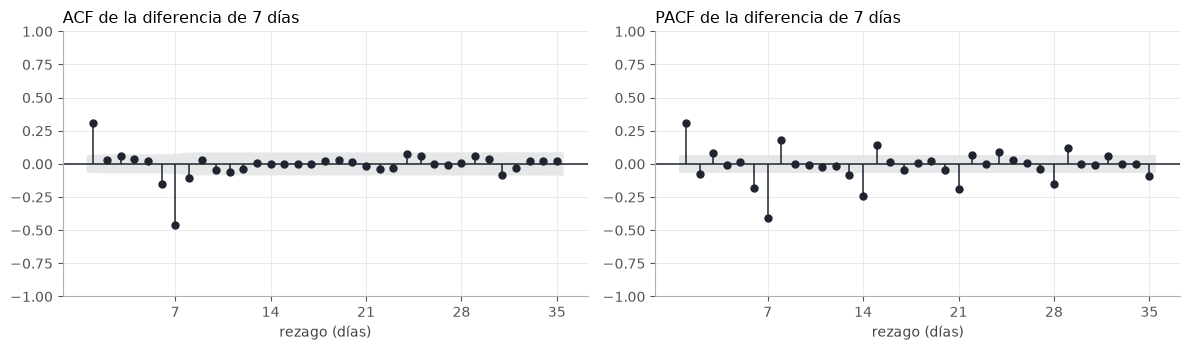

In [5]:
from matplotlib.collections import PolyCollection
d7 = y_tr.diff(7).dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
plot_acf(d7, lags=35, ax=axes[0], zero=False, color=TINTA, vlines_kwargs={"colors": TINTA}, title="ACF de la diferencia de 7 días")
plot_pacf(d7, lags=35, ax=axes[1], zero=False, method="ywm", color=TINTA, vlines_kwargs={"colors": TINTA}, title="PACF de la diferencia de 7 días")
for ax in axes:
    ax.set_xticks(range(7, 36, 7))
    ax.set_xlabel("rezago (días)")
    for c in ax.collections:
        if isinstance(c, PolyCollection):
            c.set_facecolor(GRIS)
fig.tight_layout()

Un pico negativo en el rezago 7 de la ACF, seguido de valores chicos en 14, 21 y 28, es la huella de un término MA estacional (Q = 1). Las barras de los primeros rezagos sugieren algún término AR o MA de orden bajo. La lectura de la ACF y la PACF da candidatos; para elegir entre ellos se usa un criterio como el **AIC** (criterio de información de Akaike), que premia el ajuste y penaliza la cantidad de parámetros. Menor es mejor.

Una grilla chica: p de 0 a 2, q de 0 a 1, P y Q de 0 a 1, con d = 0 y D = 1.

In [6]:
import warnings
warnings.simplefilter("ignore")   # algunos órdenes avisan que arrancan de parámetros iniciales en cero
grilla = []
for p, q, P, Q in itertools.product(range(3), range(2), range(2), range(2)):
    try:
        ajuste = SARIMAX(y_tr, order=(p, 0, q), seasonal_order=(P, 1, Q, 7)).fit(disp=False)
        grilla.append({"orden": f"({p},0,{q})({P},1,{Q})7", "p": p, "q": q, "P": P, "Q": Q, "AIC": ajuste.aic})
    except Exception as error:
        print("No ajustó", (p, q, P, Q), error)
grilla = pd.DataFrame(grilla).sort_values("AIC").reset_index(drop=True)
grilla["AIC"] = grilla["AIC"].round(1)
grilla.head(8)

,orden,p,q,P,Q,AIC
0,"(1,0,1)(1,1,1)7",1,1,1,1,23302.5
1,"(2,0,1)(0,1,1)7",2,1,0,1,23302.5
2,"(1,0,1)(0,1,1)7",1,1,0,1,23302.6
3,"(2,0,1)(1,1,1)7",2,1,1,1,23302.8
4,"(2,0,0)(1,1,1)7",2,0,1,1,23303.1
5,"(2,0,0)(0,1,1)7",2,0,0,1,23303.1
6,"(1,0,0)(1,1,1)7",1,0,1,1,23303.2
7,"(1,0,0)(0,1,1)7",1,0,0,1,23303.2


In [7]:
mejor = grilla.iloc[0]
orden, orden_est = (int(mejor.p), 0, int(mejor.q)), (int(mejor.P), 1, int(mejor.Q), 7)
sarima = SARIMAX(y_tr, order=orden, seasonal_order=orden_est).fit(disp=False)
pred_sarima = sarima.get_forecast(h)
pronosticos["SARIMA"] = pred_sarima.predicted_mean.values
print("Orden elegido:", mejor.orden)
print(sarima.summary().tables[1])

Orden elegido: (1,0,1)(1,1,1)7
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5505      0.102      5.402      0.000       0.351       0.750
ma.L1         -0.1065      0.112     -0.948      0.343      -0.326       0.114
ar.S.L7        0.0842      0.045      1.852      0.064      -0.005       0.173
ma.S.L7       -0.8663      0.030    -29.168      0.000      -0.925      -0.808
sigma2       3.01e+10   2.75e-12   1.09e+22      0.000    3.01e+10    3.01e+10


## 3. SARIMAX: variables externas

La X de SARIMAX es por *exógenas*: variables que no salen de la propia serie. El modelo es una regresión de los pasajeros sobre esas variables, con errores que siguen un SARIMA. Cada coeficiente se lee como en una regresión: cuántos pasajeros cambia el día cuando la variable pasa de 0 a 1 (o por cada milímetro de lluvia).

Para pronosticar hay que conocer las variables externas en los días de la prueba. El calendario se conoce de antemano; la lluvia, no: acá se usa la lluvia observada, lo que equivale a suponer un pronóstico del tiempo perfecto.

Primero, una versión que marca todos los feriados, caigan el día que caigan:

In [8]:
EXOG_TODOS = ["feriado_todos", "puente", "no_laborable", "lluvia_mm"]
sarimax_todos = SARIMAX(y_tr, exog=tr[EXOG_TODOS], order=orden, seasonal_order=orden_est).fit(disp=False)
pred_todos = sarimax_todos.get_forecast(h, exog=te[EXOG_TODOS]).predicted_mean
domingos = te.index[te.index.day_of_week == 6]
print("Coeficiente de feriado_todos:", num(sarimax_todos.params["feriado_todos"]))
print("MAPE en junio:", num(metricas(y_te, pred_todos)["MAPE"], 1), "%")
pd.DataFrame({"real": y_te.loc[domingos], "pronóstico": pred_todos.loc[domingos].round()}).rename_axis("domingos de junio")

Coeficiente de feriado_todos: -405.284
MAPE en junio: 17,3 %


,real,pronóstico
domingos de junio,,
2025-06-01,195959.0,335661.0
2025-06-08,207776.0,337774.0
2025-06-15,195282.0,338413.0
2025-06-22,180744.0,337328.0


Los domingos de junio quedan muy por encima de lo real. El efecto de `feriado_todos` es una cantidad fija de pasajeros, que se resta igual a un martes que a un domingo. Pero un feriado que cae sábado o domingo cambia poco, porque ese día ya viaja poca gente; el último domingo del entrenamiento, el 25 de mayo de 2025, fue feriado. El modelo compensa con el resto de sus piezas y, con la diferencia estacional de 7 días, el error se arrastra a los domingos siguientes.

La versión que marca solo los feriados de lunes a viernes:

In [9]:
EXOG = ["feriado", "puente", "no_laborable", "lluvia_mm"]
sarimax = SARIMAX(y_tr, exog=tr[EXOG], order=orden, seasonal_order=orden_est).fit(disp=False)
pred_sarimax = sarimax.get_forecast(h, exog=te[EXOG])
pronosticos["SARIMAX"] = pred_sarimax.predicted_mean.values

ic = sarimax.conf_int().loc[EXOG]
coef = pd.DataFrame({"coeficiente": sarimax.params[EXOG], "IC 95 % inferior": ic[0], "IC 95 % superior": ic[1], "p-valor": sarimax.pvalues[EXOG]})
coef.round({"coeficiente": 0, "IC 95 % inferior": 0, "IC 95 % superior": 0, "p-valor": 4})

,coeficiente,IC 95 % inferior,IC 95 % superior,p-valor
feriado,-537662.0,-569140.0,-506185.0,0.0000
puente,-523062.0,-596281.0,-449843.0,0.0000
no_laborable,-364825.0,-407446.0,-322205.0,0.0000
lluvia_mm,-1304.0,-1943.0,-664.0,0.0001


Los coeficientes de `feriado` y `puente` son caídas de cientos de miles de pasajeros respecto de un día hábil. El de la lluvia es chico por milímetro, pero una tormenta de 30 o 40 mm lo multiplica. El SARIMA sin variables externas tiene que absorber todo eso en sus errores.

## 4. Intervalos de predicción

Los dos modelos dan intervalos (acá, del 80 %). Sin variables externas, el SARIMA no sabe que el 16 y el 20 de junio son feriados.

,días afuera,ancho el día 1,ancho el día 28
SARIMA,"16/6, 20/6",444.680,528.082
SARIMAX,ninguno,233.092,391.931


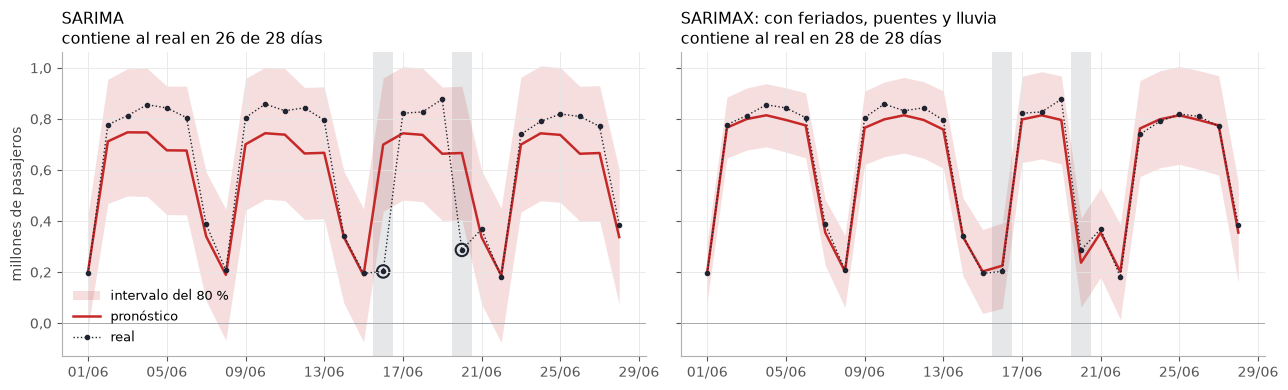

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
resumen = {}
for ax, (nombre, pr) in zip(axes, (("SARIMA", pred_sarima), ("SARIMAX: con feriados, puentes y lluvia", pred_sarimax))):
    banda = pr.conf_int(alpha=0.2)
    lo, hi = banda.iloc[:, 0], banda.iloc[:, 1]
    afuera = (y_te < lo) | (y_te > hi)
    for f in fer_te:
        ax.axvspan(f - pd.Timedelta(hours=12), f + pd.Timedelta(hours=12), color=GRIS, alpha=0.25, lw=0)
    ax.fill_between(banda.index, lo, hi, color=ROJO, alpha=0.15, lw=0, label="intervalo del 80 %")
    ax.plot(banda.index, pr.predicted_mean, color=ROJO, lw=1.8, label="pronóstico")
    ax.plot(y_te.index, y_te.values, color=TINTA, ls=":", marker="o", ms=3, lw=1, label="real")
    ax.scatter(y_te.index[afuera], y_te[afuera], s=80, facecolors="none", edgecolors=TINTA, lw=1.5)
    ax.axhline(0, color=GRIS, lw=0.6)
    ax.set_title(f"{nombre}\ncontiene al real en {int((~afuera).sum())} de {h} días")
    ax.yaxis.set_major_formatter(en_millones)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    resumen[nombre.split(":")[0]] = {"días afuera": ", ".join(f"{d.day}/{d.month}" for d in y_te.index[afuera]) or "ninguno",
                                    "ancho el día 1": num((hi - lo).iloc[0]), f"ancho el día {h}": num((hi - lo).iloc[-1])}
axes[0].set_ylabel("millones de pasajeros")
axes[0].legend(loc="lower left")
fig.tight_layout()
pd.DataFrame(resumen).T

Con las variables externas el intervalo es mucho más angosto, porque una parte grande de la variabilidad que el SARIMA trataba como ruido ahora está explicada.

## 5. Gradient boosting con rezagos

Otra forma de pronosticar es convertir la serie en una tabla: una fila por día, con columnas que resumen lo que se sabía antes, y usar cualquier modelo de regresión. El problema es que, para pronosticar 28 días, el valor de ayer no se conoce (salvo el primer día). Una solución es usar solo **rezagos de 28 días o más**: con los datos hasta el 31 de mayo se arman todas las filas de junio sin usar pronósticos propios como dato.

Variables: pasajeros de hace 28, 35, 42 y 364 días, la media de los 28 días que terminan hace 28 días, el calendario (día de la semana, mes, día del mes, feriados) y el clima.

In [11]:
X = pd.DataFrame(index=df.index)
for k in (28, 35, 42, 364):
    X[f"rezago_{k}"] = df["pax"].shift(k)
X["media_28_hace_28"] = df["pax"].shift(28).rolling(28, min_periods=20).mean()
X["dia_semana"] = df.index.day_of_week
X["mes"] = df.index.month
X["dia_mes"] = df.index.day
for c in ("feriado", "puente", "no_laborable", "lluvia_mm", "temperatura"):   # feriados de lunes a viernes
    X[c] = df[c]
y = df["pax"]

ejemplo = X.loc["2025-06-09":"2025-06-15"].copy()
ejemplo["pax (objetivo)"] = y.loc[ejemplo.index]
ejemplo.round(1)

,rezago_28,rezago_35,rezago_42,rezago_364,media_28_hace_28,dia_semana,mes,dia_mes,feriado,puente,no_laborable,lluvia_mm,temperatura,pax (objetivo)
fecha,,,,,,,,,,,,,,
2025-06-09,798755.0,753913.0,781207.0,645143.0,584808.1,0,6,9,0,0,0,0.0,8.9,805162.0
2025-06-10,821226.0,804825.0,830122.0,641940.0,584690.7,1,6,10,0,0,0,0.0,9.5,858160.0
2025-06-11,814279.0,831087.0,854583.0,670501.0,584467.8,2,6,11,0,0,0,0.0,11.7,832061.0
2025-06-12,822861.0,840089.0,170226.0,704860.0,601262.4,3,6,12,0,0,0,0.0,12.5,843346.0
2025-06-13,671244.0,817283.0,405823.0,674674.0,616940.5,4,6,13,0,0,0,12.4,12.8,795145.0
2025-06-14,249175.0,403867.0,358294.0,313172.0,614938.5,5,6,14,0,0,0,13.1,11.3,342724.0
2025-06-15,208727.0,217957.0,184331.0,142146.0,616134.8,6,6,15,0,0,0,0.0,9.1,195282.0


In [12]:
filas_tr = X.index.isin(tr.index) & y.notna()
gb = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=31, random_state=0)
gb.fit(X[filas_tr], y[filas_tr])
X_te = X.loc[te.index]
pronosticos["Gradient boosting"] = gb.predict(X_te)
print("Filas de entrenamiento:", int(filas_tr.sum()))
print("MAPE en junio de 2025:", num(metricas(y_te, pronosticos["Gradient boosting"])["MAPE"], 1), "%")

Filas de entrenamiento: 879
MAPE en junio de 2025: 12,7 %


### Importancia por permutación

Para cada variable: se mezclan al azar sus valores en los 28 días de prueba, se vuelve a pronosticar y se mide cuánto sube el MAE. Si sube mucho, el modelo depende de esa variable. Se repite 30 veces y se promedia.

Variables constantes en la prueba: ['mes', 'puente', 'no_laborable']


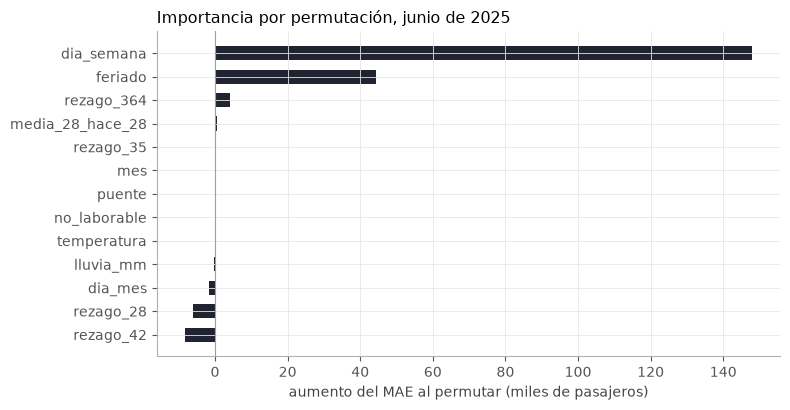

In [13]:
imp = permutation_importance(gb, X_te, y_te, n_repeats=30, random_state=0, scoring="neg_mean_absolute_error")
importancia = pd.Series(imp.importances_mean, index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(importancia.index, importancia.values, color=TINTA, height=0.6)
ax.axvline(0, color=GRIS, lw=0.8)
ax.xaxis.set_major_formatter(en_miles)
ax.set_xlabel("aumento del MAE al permutar (miles de pasajeros)")
ax.set_title("Importancia por permutación, junio de 2025")
fig.tight_layout()
print("Variables constantes en la prueba:", [c for c in X.columns if X_te[c].nunique() == 1])

La importancia depende del período de prueba: una variable que no varía en esos 28 días (todos son de junio, por ejemplo) no puede tener importancia, aunque el modelo la use en otros meses.

## 6. Comparación

In [14]:
info = {
    "Ingenuo estacional": "última semana",
    "Promedio de 4 semanas": "últimas cuatro semanas",
    "Holt-Winters": "historia: nivel, tendencia y ciclo semanal",
    "SARIMA": "historia: ciclo semanal y errores pasados",
    "SARIMAX": "SARIMA más feriados, puentes y lluvia",
    "Gradient boosting": "rezagos de 28 días o más, calendario y clima",
}
comparacion = pd.DataFrame({k: metricas(y_te, p) for k, p in pronosticos.items()}).T
comparacion.insert(0, "información que usa", pd.Series(info))
comparacion = comparacion.sort_values("MAPE")
comparacion.round({"MAE": 0, "RMSE": 0, "MAPE": 1})

,información que usa,MAE,RMSE,MAPE
SARIMAX,"SARIMA más feriados, puentes y lluvia",25390.0,31700.0,4.8
Gradient boosting,"rezagos de 28 días o más, calendario y clima",79222.0,91258.0,12.7
Promedio de 4 semanas,últimas cuatro semanas,59094.0,140810.0,19.5
Ingenuo estacional,última semana,67311.0,143660.0,20.0
SARIMA,historia: ciclo semanal y errores pasados,107351.0,151780.0,24.0
Holt-Winters,"historia: nivel, tendencia y ciclo semanal",90708.0,150627.0,27.9


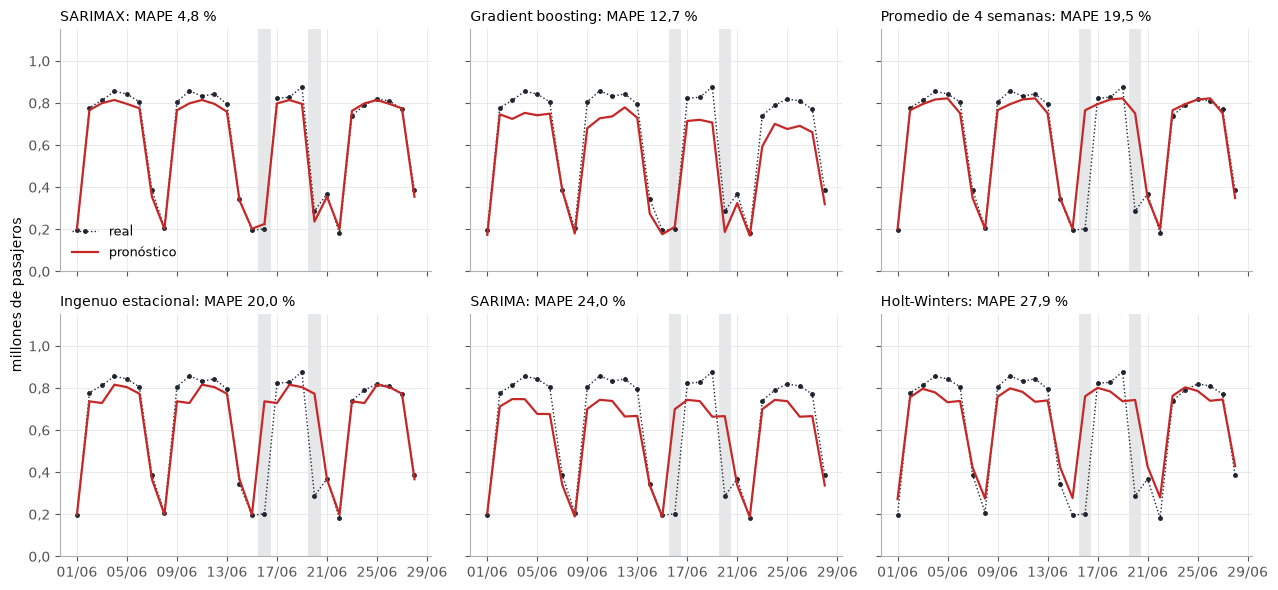

In [15]:
orden_modelos = list(comparacion.index)
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True, sharey=True)
for ax, nombre in zip(axes.flat, orden_modelos):
    for f in fer_te:
        ax.axvspan(f - pd.Timedelta(hours=12), f + pd.Timedelta(hours=12), color=GRIS, alpha=0.25, lw=0)
    ax.plot(y_te.index, y_te.values, color=TINTA, ls=":", marker="o", ms=2.5, lw=1, label="real")
    ax.plot(y_te.index, pronosticos[nombre], color=ROJO, lw=1.6, label="pronóstico")
    ax.set_title(f"{nombre}: MAPE {num(comparacion.loc[nombre, 'MAPE'], 1)} %", fontsize=10)
    ax.yaxis.set_major_formatter(en_millones)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
axes[0, 0].legend(loc="lower left")
axes[0, 0].set_ylim(0, 1.15e6)
fig.supylabel("millones de pasajeros", fontsize=10)
fig.tight_layout()

El orden puede cambiar con otro período de prueba (ver la validación con origen móvil del cuaderno 04). En junio de 2025 buena parte de la diferencia entre modelos está en los dos feriados, que solo aciertan los modelos que usan el calendario.

## 7. Otras alternativas

- **Prophet** (Meta) ajusta una tendencia por tramos, ciclos semanales y anuales con series de Fourier y efectos de feriados que se le pasan como tabla. Es fácil de usar y tolera días faltantes.
- **Redes recurrentes** (LSTM) y **Transformers** para series: tienen sentido con muchas series relacionadas o con muchos datos; con una sola serie diaria, rara vez superan a los modelos de este cuaderno.

Si Prophet está instalado (en Colab suele estarlo), la celda siguiente lo ajusta con los mismos datos y los mismos feriados. Si no, sigue sin él.

In [16]:
import logging
import warnings
logging.getLogger("prophet.plot").setLevel(logging.CRITICAL)
warnings.filterwarnings("ignore", message="IProgress not found")
try:
    from prophet import Prophet
except ImportError:
    Prophet = None
    print("Prophet no está instalado; se puede instalar con  pip install prophet")

if Prophet is not None:
    logging.getLogger("cmdstanpy").disabled = True   # silencia los mensajes del optimizador
    historia = y_tr.reset_index()
    historia.columns = ["ds", "y"]
    especiales = pd.DataFrame({"ds": fer["fecha"], "holiday": np.where(es_puente, "puente", fer["caracter_legal"])})
    especiales = especiales[especiales["ds"].dt.day_of_week < 5]   # los mismos días especiales: de lunes a viernes
    m = Prophet(holidays=especiales, weekly_seasonality=True, yearly_seasonality=True, daily_seasonality=False)
    m.fit(historia)
    futuro = m.make_future_dataframe(periods=h)
    pred_prophet = m.predict(futuro).set_index("ds")["yhat"].loc[TEST_DESDE:TEST_HASTA]
    pronosticos["Prophet"] = pred_prophet.values
    print("Prophet, junio de 2025:", {k: num(v, 1) for k, v in metricas(y_te, pred_prophet).items()}, "(comparar con la tabla de la sección 6)")

Prophet, junio de 2025: {'MAE': '55.746,8', 'RMSE': '67.504,5', 'MAPE': '9,4'} (comparar con la tabla de la sección 6)


## Para seguir

1. Agregar la temperatura al SARIMAX, o reemplazar los milímetros de lluvia por categorías (sin lluvia, 1 a 15 mm, más de 15 mm). ¿Cambian los coeficientes y el error?
2. Entrenar el gradient boosting sin los rezagos (solo calendario y clima) y comparar el MAPE. ¿Cuánto aportan los pasajeros de hace 28 días o más?
3. Repetir la comparación con otro mes de prueba (por ejemplo, octubre de 2025) y con el origen móvil del cuaderno 04 para SARIMAX y gradient boosting. ¿Se mantiene el orden?